<a href="https://colab.research.google.com/github/khushijaiswal4455-code/Image_pixel_manipulator/blob/main/image_pixel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


1. Create a blank 200x200x3 image with np.zeros(dtype=np.uint8) and fill regions with np.full


In [2]:
image = np.zeros((200, 200, 3), dtype=np.uint8)

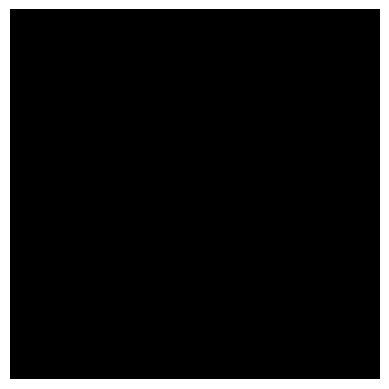

In [4]:
plt.imshow(image)
plt.axis("off")
plt.show()

In [5]:
# Fill different regions with colors
image[0:100, 0:100] = np.full((100, 100, 3), [255, 0, 0], dtype=np.uint8)       # red
image[0:100, 100:200] = np.full((100, 100, 3), [0, 255, 0], dtype=np.uint8)     # Green
image[100:200, 0:100] = np.full((100, 100, 3), [0, 0, 255], dtype=np.uint8)     # Blue
image[100:200, 100:200] = np.full((100, 100, 3), [255, 255, 0], dtype=np.uint8) # Yellow

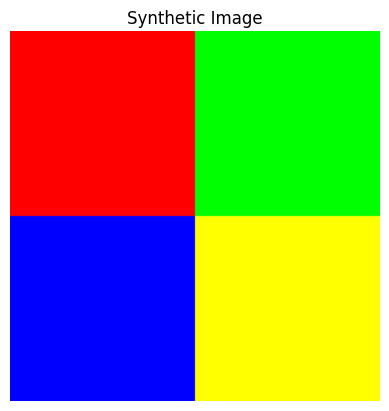

In [6]:
plt.imshow(image)
plt.title("Synthetic Image")
plt.axis("off")
plt.show()

2. Draw color blocks and stripes using 3D slicing img[10:60, 20:90, 0]

In [22]:
# color blocks
image[10:60, 20:90, 0] = 255
image[10:60, 20:90, 1] = 100
image[70:120, 20:90, 1] = 255
image[70:120, 20:90, 0] = 255

In [23]:
# horizontal stripes
image[130:140, :, 0] = 255
image[140:150, :, 1] = 255
image[150:170, :, 1] = 255

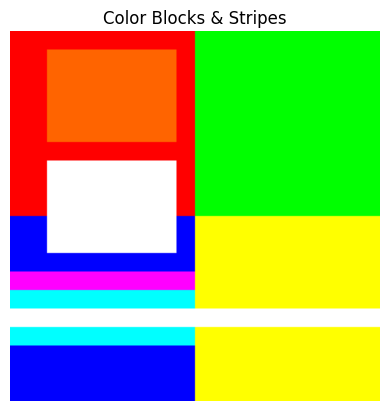

In [24]:
# image
plt.imshow(image)
plt.title("Color Blocks & Stripes")
plt.axis("off")
plt.show()

3. Crop, flip (negative step slicing) and extract single R/G/B channels

In [26]:
# Create a sample RGB image
img = np.zeros((200, 200, 3), dtype=np.uint8)

In [27]:
# Add colors to the image
img[:, :, 0] = 255
img[50:150, 50:150, 1] = 255

In [28]:
# 1. Crop the image
crop = img[50:150, 50:150, :]

In [29]:
# 2. Flip the image using negative-step slicing
flip_horizontal = img[:, ::-1, :]
flip_vertical = img[::-1, :, :]

In [30]:
# 3. Extract individual RGB channels
red = img[:, :, 0]
green = img[:, :, 1]
blue = img[:, :, 2]

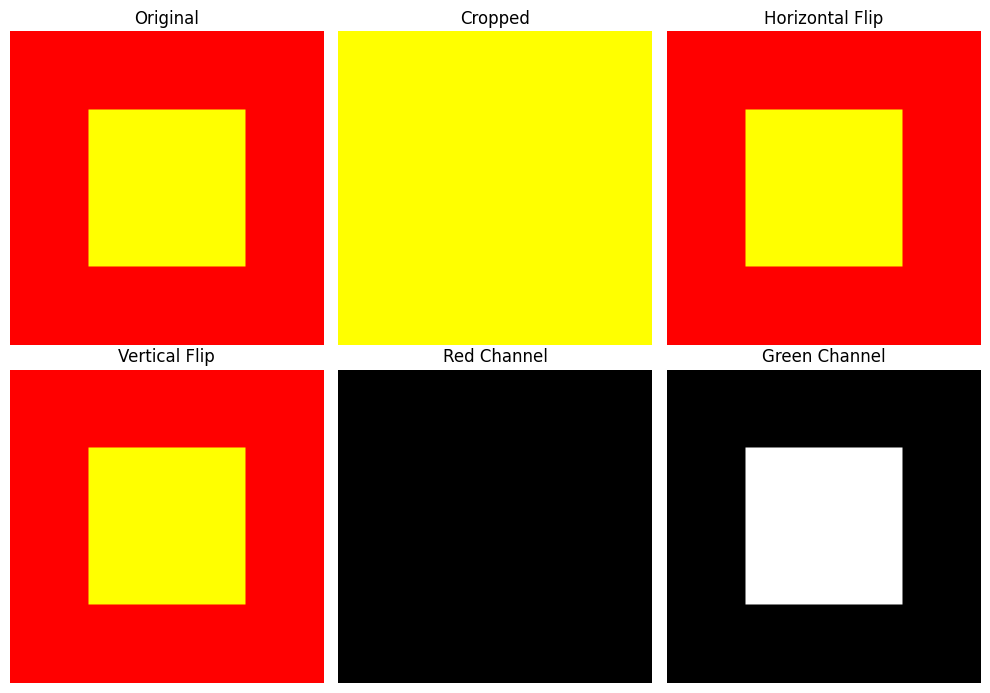

In [31]:
# Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 3, 1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(crop)
plt.title("Cropped")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(flip_horizontal)
plt.title("Horizontal Flip")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(flip_vertical)
plt.title("Vertical Flip")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(red, cmap="gray")
plt.title("Red Channel")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(green, cmap="gray")
plt.title("Green Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

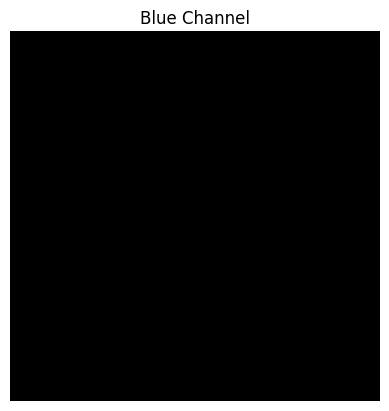

In [43]:
# Display blue channel separately
plt.imshow(blue, cmap="gray")
plt.title("Blue Channel")
plt.axis("off")
plt.show()

In [33]:
# Create image
img = np.zeros((200, 200, 3), dtype=np.uint8)
img[50:150, 50:150] = [255, 0, 0]

In [34]:
# Crop image
crop = img[50:150, 50:150]

In [35]:
# Flip image using negative slicing
flip = img[::-1, ::-1]

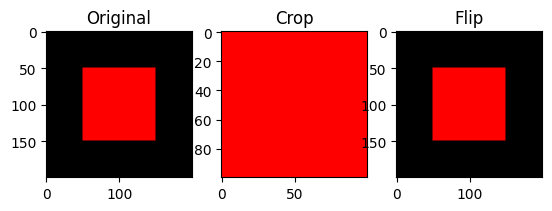

In [36]:
# Display images
plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original")

plt.subplot(1, 3, 2)
plt.imshow(crop)
plt.title("Crop")

plt.subplot(1, 3, 3)
plt.imshow(flip)
plt.title("Flip")

plt.show()

In [37]:
# Create a blank RGB image
img = np.zeros((200, 200, 3), dtype=np.uint8)

In [41]:
# Add colors
img[:, :, 0] = 255   # Red
img[:, :, 1] = 150   # Green
img[:, :, 2] = 100   # Blue

In [42]:
# Extract RGB channels
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

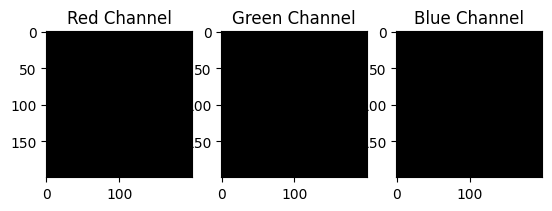

In [40]:
# Display channels
plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray")
plt.title("Red Channel")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray")
plt.title("Green Channel")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray")
plt.title("Blue Channel")

plt.show()

4. Brighten/darken using astype(float32) then cast back to uint8; apply a
mask to find bright pixels

In [44]:
# Create a sample RGB image
img = np.zeros((200, 200, 3), dtype=np.uint8)
img[30:170, 30:170] = [100, 150, 200]

In [45]:
# 1. Brighten the image
bright = img.astype(np.float32)
bright = bright + 50
bright = np.clip(bright, 0, 255).astype(np.uint8)

In [46]:
# 2. Darken the image
dark = img.astype(np.float32)
dark = dark - 50
dark = np.clip(dark, 0, 255).astype(np.uint8)

In [47]:
# 3. Find bright pixels using a mask
mask = np.mean(img, axis=2) > 120

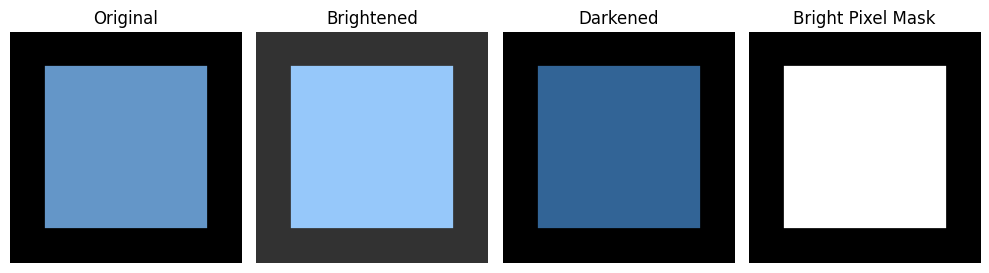

Number of bright pixels: 19600


In [48]:
# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 4, 1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(bright)
plt.title("Brightened")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(dark)
plt.title("Darkened")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(mask, cmap="gray")
plt.title("Bright Pixel Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of bright pixels:", np.sum(mask))

5. Compare memory of uint8 vs float64 image using nbytes and show with
plt.imshow

In [ ]:
# Create a 200x200x3 image using uint8
img1 = np.zeros((200, 200, 3), dtype=np.uint8)